# Week 4 — Sentiment Anomaly Detection and Clustering Teach-Back
**RGBFS | Grace | Week 4**

**Objectives:** Detect unusual SEC sentiment changes and explain the clustering methodology used in Weeks 2–3.

**Primary deliverable:** `sentiment_anomaly_flags.csv`. This analysis uses filing-to-filing changes and section-specific modified Z-scores (MAD), rather than a rolling daily baseline, because daily scores repeat between filings. Run cells in order from the RGBFS project. Recorded interpretations describe the supplied 2022 run; update them if the input changes.

## 1. Imports and configuration
Install team dependencies with `python -m pip install -r requirements.txt`. Use the project virtual environment. The primary threshold is 3.5.

In [21]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find project root whether the notebook kernel starts in RGBFS or RGBFS/notebooks.
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / 'notebooks').is_dir() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open the RGBFS project in VS Code and run the notebook from RGBFS or RGBFS/notebooks.')
OUTPUT_DIR = ROOT / 'notebooks' / 'outputs' / 'grace_week4'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Team-generated daily SEC sentiment panel.
SENTIMENT_FILE = "data/processed/features/sec_sentiment_daily.parquet"
MAD_THRESHOLD = 3.5

print('Project:', ROOT)
print('Output folder:', OUTPUT_DIR)

Project: C:\Users\dayan\Downloads\RGBFS
Output folder: C:\Users\dayan\Downloads\RGBFS\notebooks\outputs\grace_week4


## 2. Load sentiment data
Input: `data/processed/features/sec_sentiment_daily.parquet`, generated by `04_sentiment_full_corpus.ipynb` from SEC paragraphs. Each row represents a trading date, ticker and filing section.

| Column | Meaning |
|---|---|
| date | Trading date of daily panel |
| ticker | Stock symbol |
| section_group | MD&A or Risk Factors |
| average_sentiment | Average sentiment score |
| tone_change | Upstream change measure |
| paragraphs | Paragraph count |
| source_filing_trading_date | Trading date associated with source filing |

Missing scores are not replaced with zero.

In [22]:
def read_data(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Sentiment file not found: {path}')
    if path.suffix.lower() == '.csv':
        return pd.read_csv(path)
    if path.suffix.lower() in {'.parquet', '.pq'}:
        return pd.read_parquet(path)
    raise ValueError('Sentiment file must be CSV or Parquet.')

chosen_file = ROOT / SENTIMENT_FILE
raw = read_data(chosen_file)
required = {'date', 'ticker', 'section_group', 'average_sentiment', 'tone_change', 'paragraphs', 'source_filing_trading_date'}
missing = required.difference(raw.columns)
if missing:
    raise ValueError(f'Missing required columns: {sorted(missing)}')
raw['date'] = pd.to_datetime(raw['date'], errors='raise')
raw['source_filing_trading_date'] = pd.to_datetime(raw['source_filing_trading_date'], errors='raise')
raw['average_sentiment'] = pd.to_numeric(raw['average_sentiment'], errors='raise')
print('Selected file:', chosen_file)
print('Rows/columns:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.head())

Selected file: C:\Users\dayan\Downloads\RGBFS\data\processed\features\sec_sentiment_daily.parquet
Rows/columns: (2510, 7)
Columns: ['date', 'ticker', 'section_group', 'average_sentiment', 'tone_change', 'paragraphs', 'source_filing_trading_date']


,date,ticker,section_group,average_sentiment,tone_change,paragraphs,source_filing_trading_date
0,2022-01-03,AAPL,MD&A,NaN,NaN,NaN,NaT
1,2022-01-04,AAPL,MD&A,NaN,NaN,NaN,NaT
2,2022-01-05,AAPL,MD&A,NaN,NaN,NaN,NaT
3,2022-01-06,AAPL,MD&A,NaN,NaN,NaN,NaT
4,2022-01-07,AAPL,MD&A,NaN,NaN,NaN,NaT


## 3. Data quality and exploratory analysis

In [23]:
print("Dataset dimensions:", raw.shape)

print("\nDate range:")
print(raw["date"].min(), "to", raw["date"].max())

print("\nNumber of unique stocks:")
print(raw["ticker"].nunique())

print("\nSEC filing sections:")
print(raw["section_group"].value_counts())

print("\nMissing values:")
print(raw.isna().sum())

print("\nAvailable sentiment observations:")
print(raw["average_sentiment"].notna().sum())

print("\nAvailable scores by ticker and section:")
print(
    raw.groupby(["ticker", "section_group"])
    ["average_sentiment"].count()
)

print("\nSentiment descriptive statistics:")
print(raw["average_sentiment"].describe())

Dataset dimensions: (2510, 7)

Date range:
2022-01-03 00:00:00 to 2022-12-30 00:00:00

Number of unique stocks:
5

SEC filing sections:
section_group
MD&A            1255
Risk Factors    1255
Name: count, dtype: int64

Missing values:
date                             0
ticker                           0
section_group                    0
average_sentiment              458
tone_change                   1673
paragraphs                     458
source_filing_trading_date     268
dtype: int64

Available sentiment observations:
2052

Available scores by ticker and section:
ticker  section_group
AAPL    MD&A             232
        Risk Factors     106
AMZN    MD&A             227
        Risk Factors     227
GOOGL   MD&A             229
        Risk Factors     165
MSFT    MD&A             235
        Risk Factors     235
NVDA    MD&A             198
        Risk Factors     198
Name: average_sentiment, dtype: int64

Sentiment descriptive statistics:
count    2052.000000
mean       -0.283413

In [24]:
# Examine sentiment availability and variation
# for each stock and SEC filing section

sentiment_summary = raw.groupby(
    ["ticker", "section_group"]
).agg(
    total_rows=("average_sentiment", "size"),
    available_scores=("average_sentiment", "count"),
    unique_scores=("average_sentiment", "nunique"),
    mean_sentiment=("average_sentiment", "mean"),
    std_sentiment=("average_sentiment", "std"),
    unique_filing_dates=("source_filing_trading_date", "nunique")
).reset_index()

sentiment_summary["missing_scores"] = (
    sentiment_summary["total_rows"]
    - sentiment_summary["available_scores"]
)

display(sentiment_summary)

,ticker,section_group,total_rows,available_scores,unique_scores,mean_sentiment,std_sentiment,unique_filing_dates,missing_scores
0,AAPL,MD&A,251,232,4,0.078284,0.062083,4,19
1,AAPL,Risk Factors,251,106,2,-0.223299,0.271570,4,145
2,AMZN,MD&A,251,227,4,-0.076988,0.059769,4,24
3,AMZN,Risk Factors,251,227,4,-0.444783,0.165979,4,24
4,GOOGL,MD&A,251,229,4,0.106258,0.038835,4,22
5,GOOGL,Risk Factors,251,165,3,-0.790734,0.173381,4,86
6,MSFT,MD&A,251,235,4,0.087290,0.055556,4,16
7,MSFT,Risk Factors,251,235,3,-0.864041,0.139687,4,16
8,NVDA,MD&A,251,198,4,-0.035464,0.137437,4,53
9,NVDA,Risk Factors,251,198,4,-0.817767,0.090220,4,53


**Interpretation:** The 2022 panel contains 2,510 rows, five companies (AAPL, AMZN, GOOGL, MSFT, NVDA) and two sections. Of these rows, 2,052 (81.75%) have sentiment scores and 458 (18.25%) do not. Each ticker-section series has only 2–4 unique scores despite repeated daily records. A daily rolling baseline would overrepresent carried-forward values.

## 4. Filing-level sentiment preparation
Retain one scored observation per ticker, section and source filing trading date. The first available daily record represents that filing-section observation.

In [25]:
# Examine sentiment at the original SEC filing level

filing_events = (
    raw.dropna(
        subset=[
            "average_sentiment",
            "source_filing_trading_date"
        ]
    )
    .sort_values("date")
    .drop_duplicates(
        subset=[
            "ticker",
            "section_group",
            "source_filing_trading_date"
        ]
    )
    .copy()
)

print("Total daily observations:", len(raw))
print("Unique filing-section observations:", len(filing_events))

display(
    filing_events[
        [
            "ticker",
            "section_group",
            "source_filing_trading_date",
            "average_sentiment",
            "tone_change"
        ]
    ].sort_values(
        [
            "ticker",
            "section_group",
            "source_filing_trading_date"
        ]
    )
)

print("\nFiling observations per series:")

display(
    filing_events.groupby(
        ["ticker", "section_group"]
    ).size().reset_index(name="filing_observations")
)

Total daily observations: 2510
Unique filing-section observations: 37


,ticker,section_group,source_filing_trading_date,average_sentiment,tone_change
19,AAPL,MD&A,2022-01-28,0.108696,NaN
82,AAPL,MD&A,2022-04-29,0.120000,0.011304
144,AAPL,MD&A,2022-07-29,-0.021739,-0.141739
208,AAPL,MD&A,2022-10-28,0.122449,NaN
270,AAPL,Risk Factors,2022-01-28,0.000000,NaN
459,AAPL,Risk Factors,2022-10-28,-0.550459,NaN
526,AMZN,MD&A,2022-02-04,0.012821,NaN
584,AMZN,MD&A,2022-04-29,-0.144928,NaN
646,AMZN,MD&A,2022-07-29,-0.102941,0.041986
710,AMZN,MD&A,2022-10-28,-0.061538,0.041403



Filing observations per series:


,ticker,section_group,filing_observations
0,AAPL,MD&A,4
1,AAPL,Risk Factors,2
2,AMZN,MD&A,4
3,AMZN,Risk Factors,4
4,GOOGL,MD&A,4
5,GOOGL,Risk Factors,3
6,MSFT,MD&A,4
7,MSFT,Risk Factors,4
8,NVDA,MD&A,4
9,NVDA,Risk Factors,4


**Interpretation:** Deduplication yields 37 filing-section observations across ten series. These are not 37 necessarily distinct filings across all companies and sections.

## 5. Calculate filing-to-filing sentiment changes
Calculate differences within each ticker and section, using consecutive available scored filings. The first observation of each series has no change.

In [26]:

# Calculate sentiment changes between consecutive filings

filing_events = filing_events.sort_values(
    [
        "ticker",
        "section_group",
        "source_filing_trading_date"
    ]
).reset_index(drop=True)

filing_events["sentiment_change"] = (
    filing_events.groupby(
        ["ticker", "section_group"]
    )["average_sentiment"].diff()
)

print("Total filing observations:", len(filing_events))

print(
    "Available sentiment changes:",
    filing_events["sentiment_change"].notna().sum()
)

print("\nSentiment change statistics by section:")

display(
    filing_events.groupby("section_group")
    ["sentiment_change"].describe()
)

display(
    filing_events[
        [
            "ticker",
            "section_group",
            "source_filing_trading_date",
            "average_sentiment",
            "sentiment_change"
        ]
    ]
)

Total filing observations: 37
Available sentiment changes: 27

Sentiment change statistics by section:


,count,mean,std,min,25%,50%,75%,max
section_group,,,,,,,,
MD&A,15.0,-0.040140,0.095913,-0.257649,-0.078127,-0.023344,0.012633,0.144188
Risk Factors,12.0,-0.061043,0.304853,-0.550459,-0.219945,-0.122423,0.219363,0.416667


,ticker,section_group,source_filing_trading_date,average_sentiment,sentiment_change
0,AAPL,MD&A,2022-01-28,0.108696,NaN
1,AAPL,MD&A,2022-04-29,0.120000,0.011304
2,AAPL,MD&A,2022-07-29,-0.021739,-0.141739
3,AAPL,MD&A,2022-10-28,0.122449,0.144188
4,AAPL,Risk Factors,2022-01-28,0.000000,NaN
5,AAPL,Risk Factors,2022-10-28,-0.550459,-0.550459
6,AMZN,MD&A,2022-02-04,0.012821,NaN
7,AMZN,MD&A,2022-04-29,-0.144928,-0.157748
8,AMZN,MD&A,2022-07-29,-0.102941,0.041986
9,AMZN,MD&A,2022-10-28,-0.061538,0.041403


**Interpretation:** There are 27 usable changes: 15 MD&A and 12 Risk Factors. Mean changes are −0.0401 and −0.0610, respectively; standard deviations are 0.0959 and 0.3049. Risk Factors changes are more variable, supporting separate section baselines.

## 6. MAD anomaly detection
Pool changes within each section. The modified Z-score is $0.6745(x-\mathrm{median})/\mathrm{MAD}$, where MAD is the median absolute deviation from the section median. Flag only scores with absolute value strictly greater than 3.5. Missing changes or zero MAD are not evaluated. This is a retrospective baseline, not a prediction model.

In [27]:

# Detect sentiment anomalies using the Modified Z-score (MAD)


anomaly_results = filing_events.copy()

anomaly_results["section_median"] = (
    anomaly_results.groupby("section_group")
    ["sentiment_change"].transform("median")
)

anomaly_results["absolute_deviation"] = (
    anomaly_results["sentiment_change"]
    - anomaly_results["section_median"]
).abs()

anomaly_results["mad"] = (
    anomaly_results.groupby("section_group")
    ["absolute_deviation"].transform("median")
)

# Avoid division by zero
valid_mad = anomaly_results["mad"].replace(0, np.nan)

# Calculate modified Z-score
anomaly_results["modified_z_score"] = (
    0.6745
    * (
        anomaly_results["sentiment_change"]
        - anomaly_results["section_median"]
    )
    / valid_mad
)

# Identify whether an observation can be evaluated
anomaly_results["evaluable"] = (
    anomaly_results["modified_z_score"].notna()
)

# Flag unusual sentiment changes
anomaly_results["anomaly_flag"] = (
    anomaly_results["modified_z_score"]
    .abs()
    .gt(MAD_THRESHOLD)
    .astype("boolean")
    .where(anomaly_results["evaluable"], pd.NA)
)

# Identify anomaly direction relative to section median
anomaly_results["anomaly_direction"] = np.select(
    [
        ~anomaly_results["evaluable"],
        anomaly_results["modified_z_score"] > MAD_THRESHOLD,
        anomaly_results["modified_z_score"] < -MAD_THRESHOLD
    ],
    [
        "Not evaluated",
        "Positive anomaly",
        "Negative anomaly"
    ],
    default="Normal"
)

print("Total filing observations:", len(anomaly_results))

print(
    "Evaluated observations:",
    anomaly_results["evaluable"].sum()
)

print(
    "Total anomalies:",
    anomaly_results["anomaly_flag"].sum()
)

Total filing observations: 37
Evaluated observations: 27
Total anomalies: 0


In [28]:
# Display detected sentiment anomalies

detected_anomalies = anomaly_results.loc[
    anomaly_results["anomaly_flag"].fillna(False)
].copy()

display(
    detected_anomalies[
        [
            "ticker",
            "section_group",
            "source_filing_trading_date",
            "average_sentiment",
            "sentiment_change",
            "modified_z_score",
            "anomaly_direction"
        ]
    ].sort_values("modified_z_score")
)

,ticker,section_group,source_filing_trading_date,average_sentiment,sentiment_change,modified_z_score,anomaly_direction


**Interpretation:** 27 of 37 observations were evaluated; ten first observations were not evaluated. Zero anomalies exceeded the primary threshold. This is a valid result, not proof that no unusual events occurred.

## 7. Threshold sensitivity analysis

In [29]:
# Sensitivity analysis for different anomaly thresholds

thresholds = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]

valid_scores = anomaly_results[
    "modified_z_score"
].dropna()

sensitivity_rows = []

for threshold in thresholds:
    positive = (valid_scores > threshold).sum()
    negative = (valid_scores < -threshold).sum()
    total = positive + negative

    sensitivity_rows.append({
        "threshold": threshold,
        "evaluated_observations": len(valid_scores),
        "positive_anomalies": positive,
        "negative_anomalies": negative,
        "total_anomalies": total,
        "anomaly_rate_pct": 100 * total / len(valid_scores)
    })

threshold_sensitivity = pd.DataFrame(sensitivity_rows)

display(threshold_sensitivity)

,threshold,evaluated_observations,positive_anomalies,negative_anomalies,total_anomalies,anomaly_rate_pct
0,1.5,27,1,3,4,14.814815
1,2.0,27,1,1,2,7.407407
2,2.5,27,0,1,1,3.703704
3,3.0,27,0,1,1,3.703704
4,3.5,27,0,0,0,0.000000
5,4.0,27,0,0,0,0.000000


**Interpretation:** Thresholds 1.5, 2.0, 2.5, 3.0, 3.5 and 4.0 yielded 4, 2, 1, 1, 0 and 0 flags, respectively. Retain 3.5 as the primary rule; lower thresholds are exploratory.

## 8. Rank unusual sentiment changes

In [30]:
# Rank sentiment changes by anomaly strength

ranked_changes = anomaly_results.copy()

ranked_changes["absolute_z_score"] = (
    ranked_changes["modified_z_score"].abs()
)

ranked_changes = ranked_changes.sort_values(
    "absolute_z_score",
    ascending=False
)

display(
    ranked_changes[
        [
            "ticker",
            "section_group",
            "source_filing_trading_date",
            "average_sentiment",
            "sentiment_change",
            "modified_z_score",
            "absolute_z_score",
            "anomaly_flag"
        ]
    ].head(10)
)

,ticker,section_group,source_filing_trading_date,average_sentiment,sentiment_change,modified_z_score,absolute_z_score,anomaly_flag
31,NVDA,MD&A,2022-08-31,-0.185185,-0.257649,-3.291037,3.291037,False
3,AAPL,MD&A,2022-10-28,0.122449,0.144188,2.353146,2.353146,False
7,AMZN,MD&A,2022-04-29,-0.144928,-0.157748,-1.887834,1.887834,False
2,AAPL,MD&A,2022-07-29,-0.021739,-0.141739,-1.662974,1.662974,False
12,AMZN,Risk Factors,2022-07-29,-0.250000,0.416667,1.484605,1.484605,False
27,MSFT,Risk Factors,2022-07-28,-0.666667,0.333333,1.255112,1.255112,False
5,AAPL,Risk Factors,2022-10-28,-0.550459,-0.550459,-1.178774,1.178774,False
20,GOOGL,Risk Factors,2022-10-26,-0.750000,0.250000,1.025620,1.025620,False
8,AMZN,MD&A,2022-07-29,-0.102941,0.041986,0.917625,0.917625,False
35,NVDA,Risk Factors,2022-08-31,-0.735294,0.209150,0.913123,0.913123,False


**Interpretation:** NVDA MD&A on August 31, 2022 had the largest absolute modified Z-score (approximately −3.3), with a raw change of −0.2576. AAPL MD&A on October 28 had the next largest absolute score. Neither exceeded 3.5.

## 9. Visualization and interpretation
### 9.1 Filing-event anomaly scores

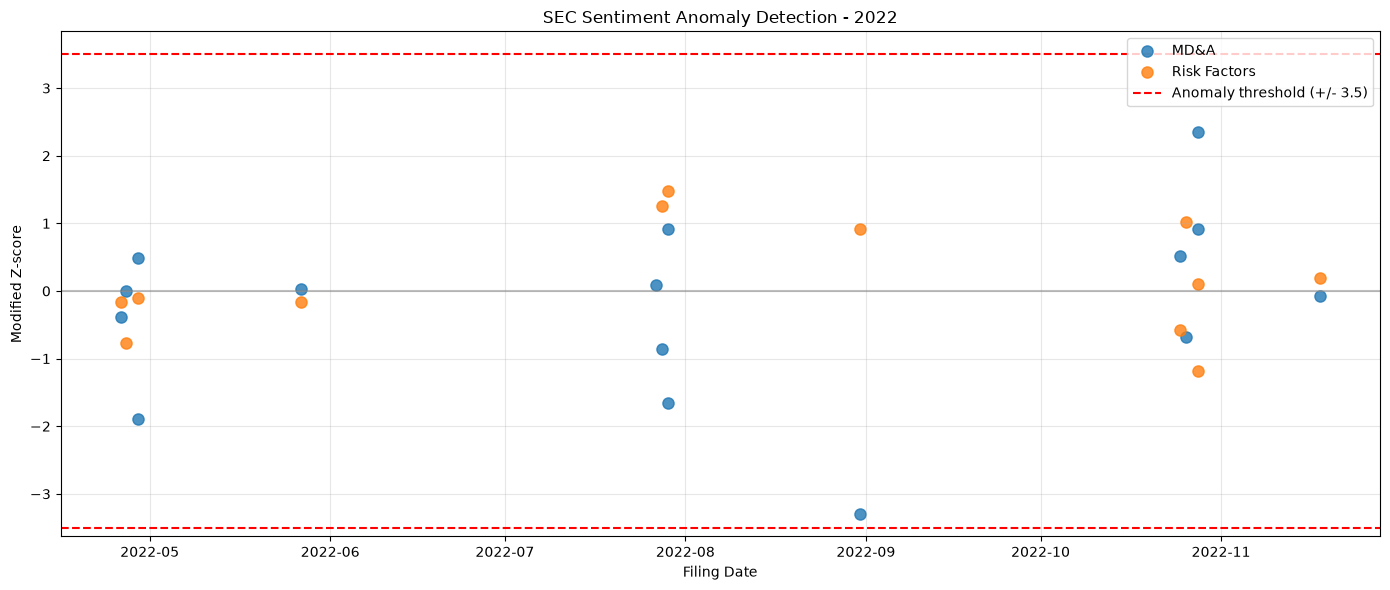

In [31]:
# Visualize modified Z-scores by SEC filing section

fig, ax = plt.subplots(figsize=(14, 6))

for section, group in anomaly_results.groupby("section_group"):

    valid = group.dropna(subset=["modified_z_score"])

    ax.scatter(
        valid["source_filing_trading_date"],
        valid["modified_z_score"],
        label=section,
        s=65,
        alpha=0.8
    )

ax.axhline(
    MAD_THRESHOLD, color="red", linestyle="--",
    label=f"Anomaly threshold (+/- {MAD_THRESHOLD})"
)

ax.axhline(-MAD_THRESHOLD, color="red", linestyle="--")
ax.axhline(0, color="gray", linestyle="-", alpha=0.5)

ax.set_title("SEC Sentiment Anomaly Detection - 2022")
ax.set_xlabel("Filing Date")
ax.set_ylabel("Modified Z-score")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sentiment_anomaly_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

All evaluated scores lie within the dashed ±3.5 boundaries. NVIDIA’s August MD&A decline is closest to a boundary.

### 9.2 Sensitivity to threshold

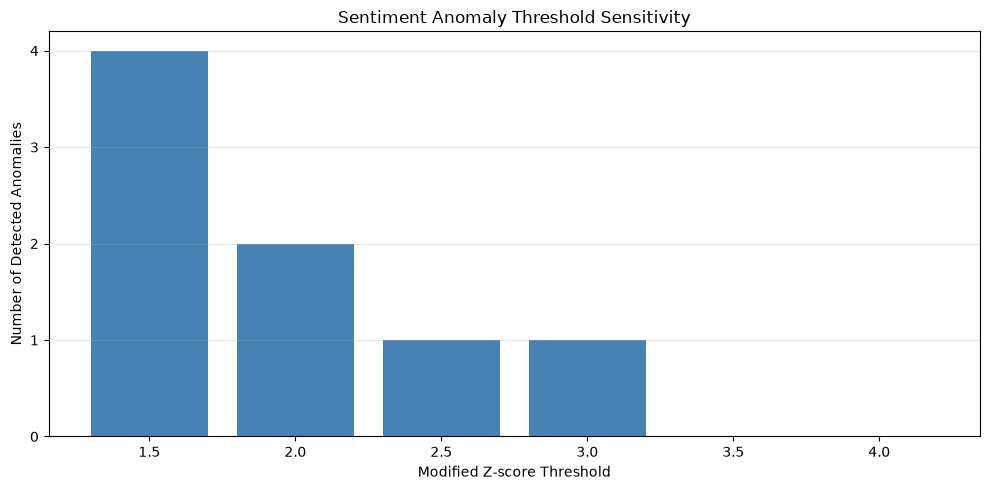

In [32]:
# Visualize the effect of anomaly threshold selection

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    threshold_sensitivity["threshold"].astype(str),
    threshold_sensitivity["total_anomalies"],
    color="steelblue"
)

ax.set_title("Sentiment Anomaly Threshold Sensitivity")
ax.set_xlabel("Modified Z-score Threshold")
ax.set_ylabel("Number of Detected Anomalies")
ax.set_yticks(range(
    int(threshold_sensitivity["total_anomalies"].max()) + 1
))

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "threshold_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Lower thresholds flag more observations; this does not establish their accuracy or false-positive rate because no ground-truth labels are available.

## 10. Export results
Save the full filing-level flag table (including unevaluated observations), ranked changes, data summary, and sensitivity table. The two charts are saved by Section 9.

In [33]:
# Save Week 4 analysis results

anomaly_results.to_csv(
    OUTPUT_DIR / "sentiment_anomaly_flags.csv",
    index=False
)

threshold_sensitivity.to_csv(
    OUTPUT_DIR / "threshold_sensitivity.csv",
    index=False
)

ranked_changes.to_csv(
    OUTPUT_DIR / "ranked_sentiment_changes.csv",
    index=False
)

sentiment_summary.to_csv(
    OUTPUT_DIR / "sentiment_data_summary.csv",
    index=False
)

print("Week 4 results saved successfully.")

print("\nOutput directory:", OUTPUT_DIR)

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

Week 4 results saved successfully.

Output directory: C:\Users\dayan\Downloads\RGBFS\notebooks\outputs\grace_week4
ranked_sentiment_changes.csv
sentiment_anomaly_detection.png
sentiment_anomaly_flags.csv
sentiment_data_summary.csv
threshold_sensitivity.csv
threshold_sensitivity.png


## 11. Limitations and final conclusion
The analysis evaluated sentiment changes for five companies during 2022. After removing repeated daily measurements, 37 filing-section observations yielded 27 evaluable changes. Section-specific modified Z-scores identified zero anomalies at the primary threshold of 3.5. Sensitivity analysis identified one negative anomaly at 3.0; NVIDIA’s August MD&A decline was the most unusual relative to its section baseline.

The small sample, missing scores, uneven filing intervals and pooling across companies limit statistical inference. Scores use the entire observed year as a retrospective reference, including later observations; they must not be interpreted as real-time signals. The study does not establish the accuracy of anomaly detection or generalize to the entire S&P 500. The recommended method and threshold are analysis choices, not team-mandated settings. A larger filing history and out-of-sample evaluation would support a stronger assessment.

The required anomaly flags table and supporting charts provide a reproducible exploratory analysis without forcing detections.

## 12. Teach-back: clustering (Weeks 2 and 3)

**What is a correlation network?** Each stock is a node; two stocks are linked when their absolute return correlation exceeds a chosen threshold. In our Week 2 prototype, we used a 60-trading-day window and an absolute-correlation threshold of **0.55**.

**What is community detection?** Greedy modularity partitions the graph into groups with comparatively strong internal connections. Modularity measures the extent to which the network has community structure relative to a null model. It is not a measure of prediction accuracy.

**Week 2 example:** The network ending **October 15, 2008** had **296 stocks**, **27,383 edges**, and **two communities** (160 and 136 stocks). Modularity was approximately **0.0964**. The sector comparison covered **250** stocks and gave **ARI ≈ 0.0787** and **NMI ≈ 0.1777**, indicating limited agreement with the available sector labels.

**Week 3 extension:** We repeated the network analysis over the historical period at approximately 20-trading-day intervals. **272 of 273** evaluation windows succeeded; the first lacked enough complete return data. Community counts and modularity varied over time.

**Limitations:** Correlation is not causation; the absolute-correlation graph treats strong positive and negative correlations as links; threshold and resolution choices affect detected communities; the sector mapping may not be historically accurate for all dates.

**Teach-back prompt:** Explain in your own words why two stocks can appear in the same detected community even when their official sectors differ.

**Teach-back answer:** Stocks in different sectors may react similarly to interest rates, liquidity shocks and market-wide news. Communities reflect observed return relationships, not industry labels. A high threshold removes weaker links; changes in resolution alter community granularity. ARI and NMI quantify partition agreement on matched stocks. A low score indicates limited alignment, not necessarily a defective clustering algorithm. Community labels are local to each window and do not establish persistent identities without explicit matching.

**Week 2 sensitivity:** Raising the threshold from 0.40 to 0.70 reduced density from 0.8855 to 0.2205 and changed the number of communities from two to four. At resolution 1.0 there were two communities; at 1.5 there were 119. The sector mapping is approximate and uses classifications that may postdate the historical windows.

**Week 3 example:** The first successful window ended April 27, 2005 (14 communities); the last ended October 29, 2026 (22 communities). These are window-specific partitions, not evidence that the same communities persisted. See `06_clustering_analysis.ipynb` and `07_clustering_over_time.ipynb` for the original analyses.